<a href="https://colab.research.google.com/github/dataanalyst-netizen/sales-data-pipeline/blob/main/Sales_Python_Practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("Namaste Python!")

Namaste Python!


In [ ]:
from google.colab import auth
auth.authenticate_user()   # login permission maangega, allow kijiye

from google.cloud import bigquery
client = bigquery.Client(project="sales-practice-515104")

df = client.query("""
    SELECT AccountName, ROUND(SUM(Total_Taxable),0) AS total
    FROM `sales-practice-515104.sales_us.sales_2026`
    GROUP BY AccountName
    ORDER BY total DESC
    LIMIT 10
""").to_dataframe()

df

,AccountName,total
0,SALUJA PAINT AND PLY KAWARDHA,12519587.0
1,IMDADI BUILDMART (CUSTOMER),12507324.0
2,SAURABH ENTERPRISES DHAMTARI,10826238.0
3,MULLA JI SHOP BHATAPARA,8266429.0
4,JAGANNATH PARASRAM RAIGARH,8129610.0
5,UMASHANKAR HARDWARE JEYPORE,7934842.0
6,BHAWANI PAINT HOUSE KANTABANJEE,7222586.0
7,EZZI HARDWARE RAJNANDGAON,7026418.0
8,FATEMEE AGENCY KOTMA,6715903.0
9,EZZI STEEL RAJNANDGAON,5478683.0


<Axes: ylabel='AccountName'>

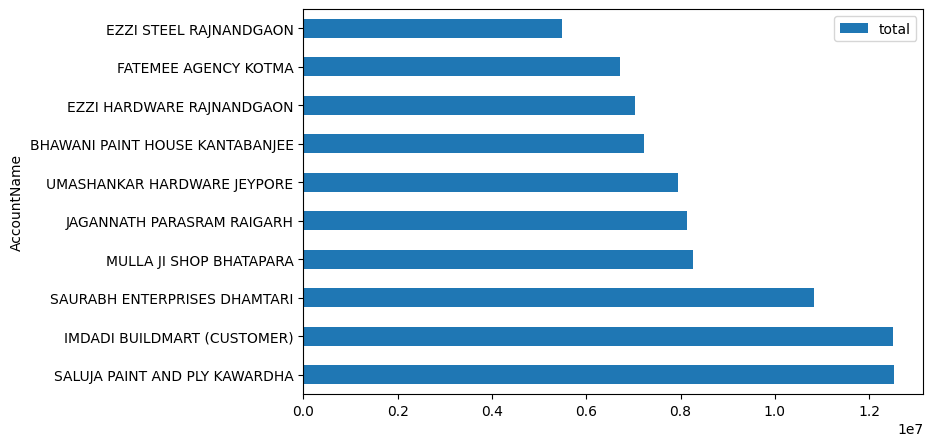

In [ ]:
df.plot(kind="barh", x="AccountName", y="total", figsize=(8, 5))

In [ ]:
df.to_excel("top_parties.xlsx", index=False)

from google.colab import files
files.download("top_parties.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Top 10 ka total:", df["total"].sum())
print("Average:", df["total"].mean())

Top 10 ka total: 86627620.0
Average: 8662762.0


In [ ]:
from google.colab import auth
auth.authenticate_user()   # login permission maangega, allow kijiye

from google.cloud import bigquery
client = bigquery.Client(project="sales-practice-515104")

df = client.query("""
    SELECT AccountName, ROUND(SUM(Total_Taxable),0) AS total
    FROM `sales-practice-515104.sales_us.sales_2026`
    GROUP BY AccountName
    ORDER BY total DESC
    LIMIT 10
""").to_dataframe()

df

,AccountName,total
0,SALUJA PAINT AND PLY KAWARDHA,12519587.0
1,IMDADI BUILDMART (CUSTOMER),12507324.0
2,SAURABH ENTERPRISES DHAMTARI,10826238.0
3,MULLA JI SHOP BHATAPARA,8266429.0
4,JAGANNATH PARASRAM RAIGARH,8129610.0
5,UMASHANKAR HARDWARE JEYPORE,7934842.0
6,BHAWANI PAINT HOUSE KANTABANJEE,7222586.0
7,EZZI HARDWARE RAJNANDGAON,7026418.0
8,FATEMEE AGENCY KOTMA,6715903.0
9,EZZI STEEL RAJNANDGAON,5478683.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.cloud import bigquery
import pandas as pd

# 1. PPC se export hui file padho
df = pd.read_csv("/content/sample_data/Sample - Superstore.csv", encoding="latin-1")
# 2. Thoda saaf karo
df.columns = [c.strip().replace(" ", "_") for c in df.columns]

# 3. BigQuery mein bhejo (purana data hatakar naya)
client = bigquery.Client(project="sales-practice-515104")
job = client.load_table_from_dataframe(
    df, "sales-practice-515104.sales_us.ppc_data",
    job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
job.result()
print("Ho gaya:", len(df), "rows")

Ho gaya: 9994 rows


In [ ]:
df.head()


,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,...,Postal_Code,Region,Product_ID,Category,Sub-Category,Product_Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,08-11-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.0,0.00,41.91
1,2,CA-2016-152156,08-11-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.0,0.00,219.58
2,3,CA-2016-138688,12-06-2016,16-06-2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.0,0.00,6.87
3,4,US-2015-108966,11-10-2015,18-10-2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.0,0.45,-383.03
4,5,US-2015-108966,11-10-2015,18-10-2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.0,0.20,2.52


In [ ]:
df.tail()

,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,...,Postal_Code,Region,Product_ID,Category,Sub-Category,Product_Name,Sales,Quantity,Discount,Profit
9989,9990,CA-2014-110422,21-01-2014,23-01-2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.25,3.0,0.2,4.10
9990,9991,CA-2017-121258,26-02-2017,03-03-2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.96,2.0,0.0,15.63
9991,9992,CA-2017-121258,26-02-2017,03-03-2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.58,2.0,0.2,19.39
9992,9993,CA-2017-121258,26-02-2017,03-03-2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.60,4.0,0.0,13.32
9993,9994,CA-2017-119914,04-05-2017,09-05-2017,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,92683,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.16,2.0,0.0,72.95


In [ ]:
df.isnull()

,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,...,Postal_Code,Region,Product_ID,Category,Sub-Category,Product_Name,Sales,Quantity,Discount,Profit
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9990,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9991,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9992,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.describe()

,Row_ID,Postal_Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858022,3.789574,0.156203,28.656973
std,2885.163629,32063.693350,623.245131,2.225110,0.206452,234.260203
min,1.000000,1040.000000,0.440000,1.000000,0.000000,-6599.980000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.730000
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.665000
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.360000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.980000


In [ ]:
df.shape

(9994, 21)